# Revision figures, single-section arm (Comments 22, 25, 30)

New or revised single-section figures for the revision of AIS 3400076. Everything is computed here from the repository models and dataset:
the test set is the original 85/10/5 split (global seed 42, as in `SINGLE_helyx_training.ipynb`).

| Output (`results/`) | Figure |
|---|---|
| `fig5b_equal_axes.pdf` | Fig. 5b with equal axis scaling (Comment 22) |
| `figS4_matched_ids.pdf` | Fig. S4 with target IDs and one color scale (SI comment 30) |
| `revision_single_test.npz` | per-sample test errors and bending angles, used by `MULTI/MULTI_revision_figures.ipynb` for Fig. 7 and Fig. S7 |

In [1]:
import glob, json, os, random
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid
from scipy.spatial.transform import Rotation as R
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split

seed = 42
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
plt.rcParams.update({"font.family": "serif", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
COL = {"const": "tab:red", "affine": "tab:green", "quad": "tab:blue"}
LBL = {"const": "Constant", "affine": "Affine", "quad": "Quadratic"}


def original_split(n=10000):
    """Same split as the training notebooks: global seed 42, then train_test_split
    (0.15) and (1/3) without random_state, i.e. drawn from the seeded NumPy stream."""
    np.random.seed(42)
    idx = np.arange(n)
    tr, tmp = train_test_split(idx, test_size=0.15)
    va, te = train_test_split(tmp, test_size=1 / 3)
    return np.sort(tr), np.sort(va), np.sort(te)


def load_fields(shards, keys, indices, per=1000):
    """Loads only the requested global indices from the dataset shards (1000 samples each)."""
    indices = np.sort(np.asarray(indices))
    out = {k: [] for k in keys}
    for s, f in enumerate(shards):
        sel = indices[(indices >= s * per) & (indices < (s + 1) * per)] - s * per
        if len(sel) == 0:
            continue
        d = torch.load(f, map_location="cpu")
        for k in keys:
            out[k].extend([d[k][i] for i in sel])
        del d
    return {k: torch.stack(v) for k, v in out.items()}


def jit(path):
    m = torch.jit.load(path, map_location="cpu"); m.eval()
    return m


def run_model(model, x, batch=16):
    with torch.no_grad():
        return np.concatenate([model(x[i:i + batch].float()).numpy() for i in range(0, len(x), batch)])


def ang_dist_deg(a, b):
    return np.degrees(np.linalg.norm((R.from_euler("zyx", b) * R.from_euler("zyx", a).inv()).as_rotvec(), axis=-1))


def bending_from_euler(e):
    return np.degrees(np.arccos(np.clip(R.from_euler("zyx", e).as_matrix()[..., 2, 2], -1, 1)))


def section_curve(S, c0, c1, c2, phi, n=1000):
    """PPC section (dimensional arc length), same discretization as the testing notebooks."""
    v = np.linspace(0, S, n)
    th = c0 * v + 0.5 * c1 * v**2 + (1 / 3) * c2 * v**3
    pi = cumulative_trapezoid(np.sin(th), v, initial=0.0)
    t = np.array([np.cos(phi) * pi, np.sin(phi) * pi, cumulative_trapezoid(np.cos(th), v, initial=0.0)])
    cp, sp, ct, st = np.cos(phi), np.sin(phi), np.cos(th[-1]), np.sin(th[-1])
    Rend = np.array([[cp**2 * (ct - 1) + 1, cp * sp * (ct - 1), cp * st],
                     [sp * cp * (ct - 1), sp**2 * (ct - 1) + 1, sp * st],
                     [-cp * st, -sp * st, ct]])
    return t, Rend


FRACS = (1 / 3, 2 / 3, 1.0)


def points_chain(params, sections):
    """(S, c0, c1, c2, phi) per section -> reference points at 1/3, 2/3, 1 of each section, chained."""
    pts, Rcum, tcum = [], np.eye(3), np.zeros(3)
    for k in range(sections):
        t, Rend = section_curve(*params[5 * k:5 * k + 5])
        tg = Rcum @ t + tcum[:, None]
        pts += [tg[:, int(f * 999)] for f in FRACS]
        tcum, Rcum = tg[:, -1], Rcum @ Rend
    return np.array(pts)


def pad_params(arr, model, sections):
    """Labels/predictions -> (S, c0, c1, c2, phi) per section, zeros for missing coefficients."""
    w, out = {"quad": 5, "affine": 4, "const": 3}[model], []
    for k in range(sections):
        p = arr[w * k:w * k + w]
        out += list(p) if model == "quad" else ([p[0], p[1], p[2], 0.0, p[3]] if model == "affine" else [p[0], p[1], 0.0, 0.0, p[2]])
    return np.array(out, dtype=float)


def scatter_targets(fig, pos, t, err, vmax, cmap, title):
    """3D target map with target IDs (1-20) and a fixed color range."""
    a = fig.add_subplot(pos, projection="3d")
    sc = a.scatter(t[:, 0], t[:, 1], t[:, 2], c=err, cmap=cmap, vmin=0, vmax=vmax, s=18, depthshade=False)
    for i, p in enumerate(t[:, :3]):
        a.text(p[0], p[1], p[2], f" {i + 1}", fontsize=5.5)
    a.set_xlabel("X [mm]", fontsize=7, labelpad=-6); a.set_ylabel("Y [mm]", fontsize=7, labelpad=-6); a.set_zlabel("Z [mm]", fontsize=7, labelpad=-6)
    a.tick_params(labelsize=5, pad=-2); a.set_title(title, fontsize=8); a.view_init(elev=22, azim=-60)
    return sc


def load_ctrl(path):
    d = np.load(path); t, m = d["target"], d["mocap"]
    pe = np.linalg.norm(t[:, :3] - m[:, :3], axis=1)
    re_ = ang_dist_deg(t[:, 3:], m[:, 3:]) if t.shape[1] == 6 else None
    return t, pe, re_


## Test-set errors

Pose CNN $f_p^1$ (position/orientation error and bending angle of each test sample) and curvature CNNs $f_C^1$
(3D error at $L/3$, $2L/3$, $L$ between the backbone of the predicted and of the labeled curvature parameters).

In [2]:
SHARDS = sorted(glob.glob("data/SINGLE_dataset/Dataset*.pt"))
tr, va, te = original_split()
d = load_fields(SHARDS, ["X_images", "y", "X_quad", "X_affine", "X_const"], te)
img, y = d["X_images"], d["y"].numpy()

pred = run_model(jit("models/vision/helyx_model.pt"), img)
pos_err = np.linalg.norm(pred[:, :3] - y[:, :3], axis=1)
rot_err = ang_dist_deg(pred[:, 3:], y[:, 3:])
bend = bending_from_euler(y[:, 3:])

curv_files = {"const": "const_model.pt", "affine": "affine_model.pt", "quad": "quadratic_model.pt"}
labels = {m: d[f"X_{m}"].numpy() for m in curv_files}
curv_pred, curv_err = {}, {}
for m, fn in curv_files.items():
    curv_pred[m] = run_model(jit(f"models/curvature/{fn}"), img)
    curv_err[m] = np.array([np.linalg.norm(points_chain(pad_params(curv_pred[m][i], m, 1), 1) - points_chain(pad_params(labels[m][i], m, 1), 1), axis=1)
                            for i in range(len(te))])

np.savez_compressed("results/revision_single_test.npz", te=te, pos_err=pos_err, rot_err=rot_err, bend=bend,
                    **{f"{m}_vs_label": e for m, e in curv_err.items()})
print(f"N = {len(te)}; position {pos_err.mean():.2f} +/- {pos_err.std():.2f} mm, orientation {rot_err.mean():.2f} +/- {rot_err.std():.2f} deg")
for m, e in curv_err.items():
    print(f"{LBL[m]:9s} per point (L/3, 2L/3, L): mean {np.round(e.mean(0), 2)}, median {np.round(np.median(e, 0), 2)}, RMSE {np.round(np.sqrt((e**2).mean(0)), 2)} mm")
r, p = spearmanr(bend, pos_err); r2, p2 = spearmanr(bend, rot_err)
print(f"Spearman bending vs position error: rho = {r:.2f} (p = {p:.1e}); vs orientation error: rho = {r2:.2f} (p = {p2:.1e})")

/home/vigno0405/miniconda3/envs/visioncontrol/lib/python3.10/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


N = 500; position 3.97 +/- 2.23 mm, orientation 3.03 +/- 1.98 deg
Constant  per point (L/3, 2L/3, L): mean [0.67 2.28 4.89], median [0.56 1.9  3.93], RMSE [0.82 2.95 6.46] mm
Affine    per point (L/3, 2L/3, L): mean [0.69 2.33 4.88], median [0.59 1.9  4.  ], RMSE [0.84 2.94 6.33] mm
Quadratic per point (L/3, 2L/3, L): mean [0.7  2.41 5.14], median [0.61 2.01 4.15], RMSE [0.9  3.21 6.98] mm
Spearman bending vs position error: rho = -0.22 (p = 6.0e-07); vs orientation error: rho = -0.14 (p = 1.4e-03)


## Fig. 5b with equal axis scaling (Comment 22)

Four test samples at the 10th, 45th, 75th and 97th percentile of the bending angle. Solid: backbone from the labels (GT); dashed: CNN prediction.
Left: current style (non-uniform axes); right: proposed, equal axes with a 20 mm scale bar.

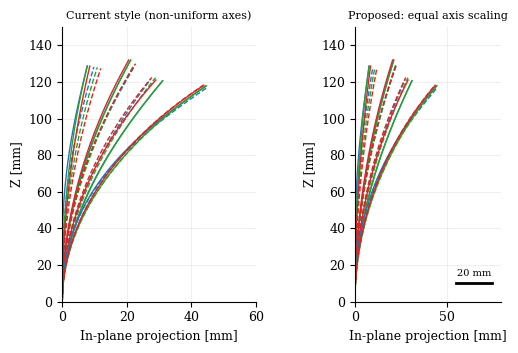

In [3]:
pick = [int(np.argmin(np.abs(bend - np.percentile(bend, q)))) for q in (10, 45, 75, 97)]


def plane_curve(p):
    S, c0, c1, c2, phi = p
    v = np.linspace(0, S, 400)
    th = c0 * v + 0.5 * c1 * v**2 + c2 * v**3 / 3
    return cumulative_trapezoid(np.sin(th), v, initial=0), cumulative_trapezoid(np.cos(th), v, initial=0)


fig, ax = plt.subplots(1, 2, figsize=(6.0, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
for j in pick:
    for m in ["quad", "affine", "const"]:
        xg, zg = plane_curve(pad_params(labels[m][j], m, 1)); xp, zp = plane_curve(pad_params(curv_pred[m][j], m, 1))
        for a in ax:
            a.plot(xg, zg, color=COL[m], lw=1); a.plot(xp, zp, color=COL[m], lw=1, ls="--")
ax[0].set_title("Current style (non-uniform axes)", fontsize=8); ax[0].set_xlim(0, 60); ax[0].set_ylim(0, 150)
ax[1].set_title("Proposed: equal axis scaling", fontsize=8); ax[1].set_aspect("equal"); ax[1].set_xlim(0, 80); ax[1].set_ylim(0, 150)
for a in ax:
    a.set_xlabel("In-plane projection [mm]"); a.set_ylabel("Z [mm]"); a.grid(alpha=0.2)
ax[1].plot([55, 75], [10, 10], "k-", lw=2); ax[1].text(65, 14, "20 mm", ha="center", fontsize=7)
plt.tight_layout(); plt.savefig("results/fig5b_equal_axes.pdf"); plt.show()

## Fig. S4 with target IDs and one color scale (SI comment 30)

Same data as Fig. S4 (`results/ControlWorkspace_jacobian.npz`, `results/ControlWorkspace_datadriven.npz`). Numbers are the target IDs of Table S8.

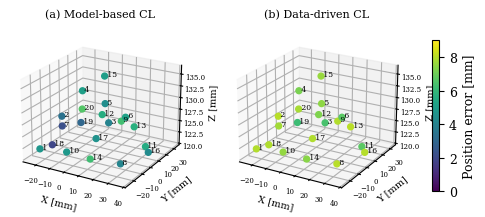

In [4]:
tA, eA, _ = load_ctrl("results/ControlWorkspace_jacobian.npz")
tB, eB, _ = load_ctrl("results/ControlWorkspace_datadriven.npz")
vmax = np.ceil(max(eA.max(), eB.max()))
fig = plt.figure(figsize=(6.4, 2.8))
scatter_targets(fig, 121, tA, eA, vmax, "viridis", "(a) Model-based CL")
sc = scatter_targets(fig, 122, tB, eB, vmax, "viridis", "(b) Data-driven CL")
fig.colorbar(sc, ax=fig.axes, shrink=0.7, label="Position error [mm]")
plt.savefig("results/figS4_matched_ids.pdf"); plt.show()